# 01 · Business understanding, data understanding and cleaning

**Capstone: is social media usage related to mental wellbeing?**
Notebooks: **01 Data & cleaning** → [02 Exploration](02_exploratory_analysis.ipynb) → [03 Modeling](03_modeling.ipynb) → [04 Findings](04_findings_and_recommendations.ipynb)

## 1. Business understanding
Social media companies, advertisers and policy makers all ask the same question: *when does heavy or habitual use go with poorer mental wellbeing, and what could be done about it?*

* **Question.** Is the time people spend on social media, and how they use it, related to their mental wellbeing score?
* **Who cares.** Advertisers and platforms (who is it safe and sensible to reach, and when?) and policy makers (what guidance should say).
* **Machine-learning task.** Classification. The 0-10 wellbeing score is split into three groups, **Low / Medium / High** (thirds of the score), and models learn to place a person in a group from their social-media habits.
* **What counts as success.** A model clearly better than guessing, whose drivers we can explain in plain language. Because the groups are balanced, we use **macro-F1** (the average of the F1 score of each group, so every group counts equally) to judge models.
* **Limit.** One survey can show *associations*, not *causes*.

## 2. Data understanding
A survey of 1,500 people: demographics, how they use social media, psychological feelings (e.g. FOMO), sleep and wellbeing.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wellbeing.config import Settings
from wellbeing.data import CLASSES, TARGET, add_target, clean, feature_frame, load_raw

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Low": "#d1495b", "Medium": "#edae49", "High": "#2e86ab"}  # one colour per wellbeing group, reused everywhere

# Settings points at the CSV and names every column; the notebooks run from the notebooks/ folder
s = Settings(data_file=Path("../data/social_media_addiction_mental_wellbeing.csv"))

In [2]:
raw = load_raw(s)  # reads the CSV and tidies column names to lower_snake_case
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

1,500 rows x 30 columns


,user_id,age,gender,occupation,relationship_status,primary_platform,daily_usage_hours,platforms_used_count,posts_per_week,late_night_usage,...,loneliness_score,self_esteem_score,sleep_quality_score,sleep_hours,productivity_loss_score,offline_relationship_quality,physical_activity_hrs_week,screen_free_time_hrs,mental_wellbeing_score,addiction_level
0,USR00001,30,Male,Working Professional,In a Relationship,YouTube,2.9,4,3,No,...,1.7,6.5,8.5,5.3,3.7,3.8,5.8,3.1,7.3,Low
1,USR00002,19,Male,Student,Married,Instagram,4.8,1,0,NaN,...,7.0,7.5,7.8,5.5,4.0,1.8,0.9,3.3,4.1,Severe
2,USR00003,40,Male,Student,In a Relationship,YouTube,NaN,4,5,No,...,5.6,5.3,6.3,NaN,5.8,2.8,0.0,1.5,5.6,High
3,USR00004,37,Female,Student,Married,Facebook,7.7,2,3,Yes,...,5.6,1.4,3.9,6.1,5.5,3.6,1.0,3.9,4.3,Severe
4,USR00005,18,Non-binary,Student,In a Relationship,TikTok,4.6,3,0,No,...,4.0,NaN,5.7,5.0,3.8,3.2,0.6,1.0,6.6,Moderate


In [3]:
raw.dtypes.value_counts().rename('columns').to_frame()  # how many numeric vs text columns

,columns
float64,16
str,10
int64,4


In [4]:
raw.describe().T.round(2)  # summary statistics for every numeric column

,count,mean,std,min,25%,50%,75%,max
age,1500.0,29.37,8.55,15.0,22.0,29.0,37.00,44.0
daily_usage_hours,1444.0,4.52,2.11,0.5,3.1,4.4,5.90,12.0
platforms_used_count,1500.0,3.24,1.68,1.0,2.0,3.0,4.00,8.0
posts_per_week,1500.0,3.94,1.95,0.0,3.0,4.0,5.00,12.0
notifications_per_day,1500.0,60.24,33.15,5.0,36.0,59.0,81.25,165.0
fomo_score,1445.0,5.45,2.18,0.0,4.0,5.5,7.00,10.0
social_comparison_score,1449.0,5.50,2.04,0.0,4.1,5.5,6.90,10.0
validation_seeking_score,1442.0,5.01,2.11,0.0,3.6,5.0,6.50,10.0
scroll_without_purpose,1500.0,5.45,2.08,0.0,4.0,5.5,6.90,10.0
anxiety_score,1452.0,5.11,2.16,0.0,3.7,5.1,6.60,10.0


### Missing values
Most columns are missing 3-5% of their values. We check which, and whether anything is *systematically* missing.

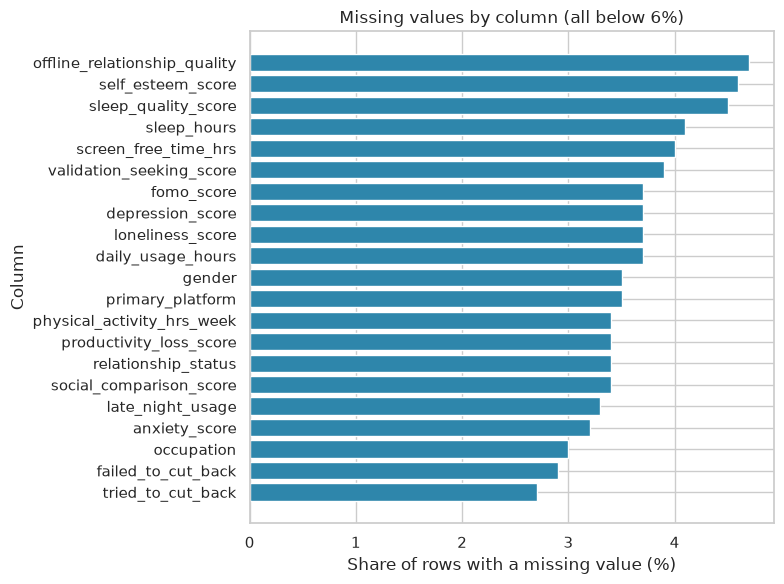

In [5]:
missing = (raw.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(missing.index, missing.values, color="#2e86ab")
ax.set_xlabel("Share of rows with a missing value (%)")
ax.set_ylabel("Column")
ax.set_title("Missing values by column (all below 6%)")
plt.tight_layout()
plt.show()

**Reading the chart.** No column is missing more than about 5% of its values and nothing looks systematic, so we do not drop rows or columns. Instead we fill the gaps **inside each cross-validation fold** during modeling (median for numbers, "Unknown" for categories), so information from the test data never leaks into training.

## 3. Data cleaning

In [6]:
df, log = clean(raw, s)  # removes duplicate people and rows with no wellbeing score, tidies text
pd.Series(log, name="count").to_frame()

,count
rows_in,1500
duplicates_removed,0
rows_without_score,0
rows_out,1500
missing_cells,1145


No duplicates and no rows without a score were found, so all 1,500 rows are kept. Next, the three wellbeing groups.

Low: score < 5.90   |   Medium: in between   |   High: score >= 7.00   (median = 6.40)


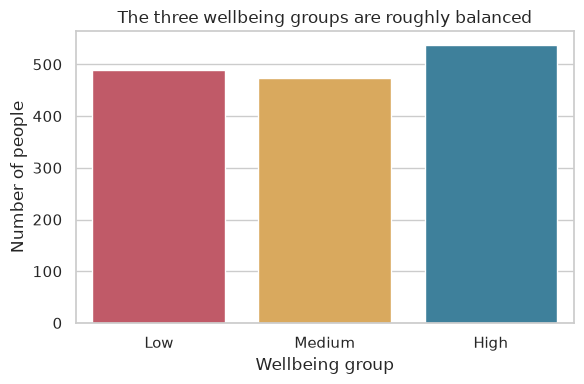

In [7]:
df, cuts = add_target(df, s)  # bottom third of scores = Low, middle third = Medium, top third = High
print(f"Low: score < {cuts['low_below']:.2f}   |   Medium: in between   |   High: score >= {cuts['high_from']:.2f}   (median = {cuts['median']:.2f})")

counts = df[TARGET].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=PALETTE, ax=ax)
ax.set_xlabel("Wellbeing group")
ax.set_ylabel("Number of people")
ax.set_title("The three wellbeing groups are roughly balanced")
plt.tight_layout()
plt.show()

## 4. Which columns are allowed to be model inputs? (avoiding leakage)
Some columns would make the question meaningless, so they are excluded:

| Excluded | Why |
|---|---|
| `user_id` | Just a label |
| `addiction_level` | Calculated from usage, so it would give away the answer to "does usage matter?" |
| `mental_wellbeing_score` | It *is* the target |
| anxiety, depression, loneliness, self-esteem, sleep quality | They *measure* mental state, i.e. wellbeing itself, not social-media behaviour. Kept for a separate benchmark in notebook 03. |

In [8]:
X = feature_frame(df, s)
print(f"{X.shape[1]} model inputs:")
print(", ".join(X.columns))

22 model inputs:
age, gender, occupation, relationship_status, primary_platform, daily_usage_hours, platforms_used_count, posts_per_week, late_night_usage, first_check_morning, notifications_per_day, fomo_score, social_comparison_score, validation_seeking_score, scroll_without_purpose, tried_to_cut_back, failed_to_cut_back, sleep_hours, productivity_loss_score, offline_relationship_quality, physical_activity_hrs_week, screen_free_time_hrs
